# Learning Rate: the most important hyperparameter

We reuse the plain MLP + Fashion-MNIST training loop (no convolutions) and change **only the learning rate** (`lr`).

**Plan**
1. Build intuition on a one-parameter toy problem
2. Set up the same MLP training loop, wrapped in a function `run(lr=...)`
3. **Predict first**, then sweep `lr` from 0.0001 to 0.5
4. Read the curves: too small, about right, too big, diverged
5. Bonus: find a good `lr` automatically (LR range test), and decay `lr` during training

## 0. Setup

In [1]:
import math, time
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import DataLoader, TensorDataset
from torchvision import datasets
import matplotlib.pyplot as plt

plt.rcParams.update({'figure.dpi': 110, 'axes.grid': True, 'grid.alpha': 0.3})
device = 'cuda' if torch.cuda.is_available() else ('mps' if torch.backends.mps.is_available() else 'cpu')
print('PyTorch', torch.__version__, '| device:', device)

PyTorch 2.11.0+cu130 | device: cuda


## 1. Intuition on a toy problem

Training = walking downhill on the loss surface. Each step is:

```
w_new = w_old - lr * gradient
```

`lr` scales how far we jump. Take the simplest bowl, `loss(w) = w^2` (minimum at w = 0, gradient = 2w), start at w = 5, and take 15 steps with four different learning rates. Pure NumPy, no PyTorch needed.

tiny (0.05)      final w after 15 steps:  1.0295
good (0.4)       final w after 15 steps:  0.0000
big (0.95)       final w after 15 steps: -1.0295
too big (1.05)   final w after 15 steps: -20.8862


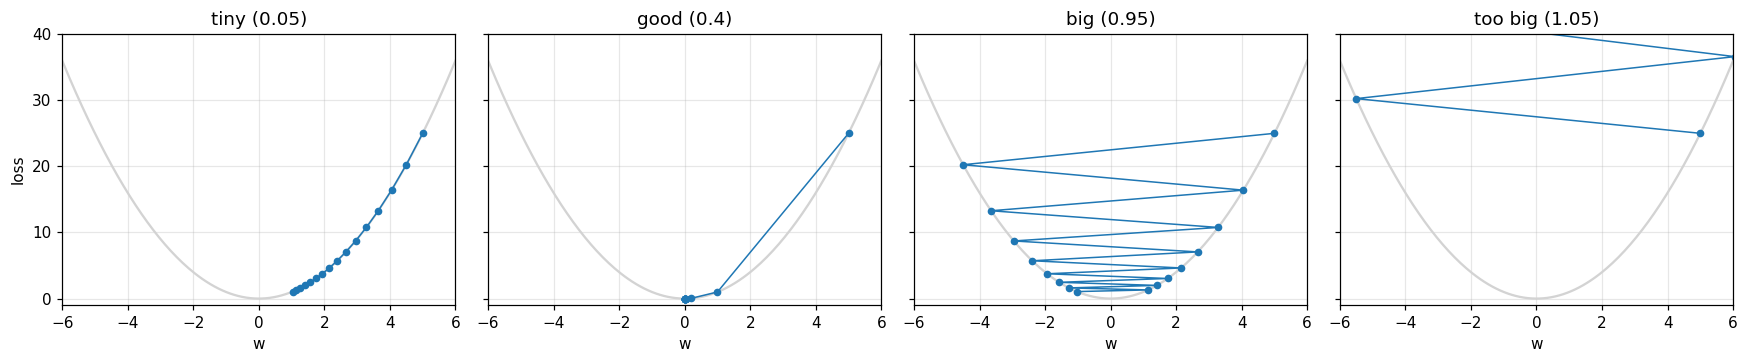

In [2]:
def descend(lr, w0=5.0, steps=15):
    ws = [w0]
    for _ in range(steps):
        w = ws[-1]
        ws.append(w - lr * 2 * w)       # w <- w - lr * dloss/dw
    return np.array(ws)

toy_lrs = {'tiny (0.05)': 0.05, 'good (0.4)': 0.4, 'big (0.95)': 0.95, 'too big (1.05)': 1.05}

fig, axes = plt.subplots(1, 4, figsize=(16, 3.4), sharey=True)
grid = np.linspace(-6, 6, 200)
for ax, (name, lr) in zip(axes, toy_lrs.items()):
    ws = descend(lr)
    ax.plot(grid, grid**2, color='lightgray')
    ax.plot(ws, ws**2, 'o-', ms=4, lw=1)
    ax.set_title(name); ax.set_xlim(-6, 6); ax.set_ylim(-1, 40); ax.set_xlabel('w')
    print(f'{name:16s} final w after 15 steps: {ws[-1]: .4f}')
axes[0].set_ylabel('loss')
plt.tight_layout(); plt.show()

- **tiny**: correct direction, but crawls (still far from 0 after 15 steps)
- **good**: reaches the bottom in a few steps
- **big**: overshoots the minimum each step and flips sides, but still shrinks
- **too big**: each overshoot is larger than the last, so the loss **grows**: divergence

For this bowl the update is `w <- w * (1 - 2*lr)`, so lr > 1 diverges. A real network has no such clean threshold, but the same four behaviors appear.

## 2. Data (Fashion-MNIST, flattened by the model)

In [3]:
mean, std = 0.2860, 0.3530
tr = datasets.FashionMNIST('data', train=True,  download=True)
te = datasets.FashionMNIST('data', train=False, download=True)

def to_tensors(ds):
    x = (ds.data.float() / 255 - mean) / std        # (N, 28, 28), normalised
    return x.unsqueeze(1), ds.targets               # (N, 1, 28, 28), (N,)

Xtr, ytr = to_tensors(tr)
Xte, yte = to_tensors(te)

train_loader = DataLoader(TensorDataset(Xtr, ytr), batch_size=64, shuffle=True)
test_loader  = DataLoader(TensorDataset(Xte, yte), batch_size=1000)
print(Xtr.shape, 'train |', Xte.shape, 'test | steps per epoch:', len(train_loader))

100%|██████████| 26.4M/26.4M [00:02<00:00, 12.5MB/s]
100%|██████████| 29.5k/29.5k [00:00<00:00, 212kB/s]
100%|██████████| 4.42M/4.42M [00:01<00:00, 3.94MB/s]
100%|██████████| 5.15k/5.15k [00:00<00:00, 12.9MB/s]


torch.Size([60000, 1, 28, 28]) train | torch.Size([10000, 1, 28, 28]) test | steps per epoch: 938


## 3. Model, evaluation, and a training function

Same plain MLP as before: `784 -> 128 -> 64 -> 10`. The `run()` function wraps the 5-step loop so we can call it with any `lr`. Every run uses the **same seed**, so the starting weights and the batch order are identical, and the *only* difference between runs is `lr`.

In [4]:
class MLP(nn.Module):
    def __init__(self):
        super().__init__()
        self.net = nn.Sequential(
            nn.Flatten(),
            nn.Linear(784, 128), nn.ReLU(),
            nn.Linear(128, 64),  nn.ReLU(),
            nn.Linear(64, 10),
        )
    def forward(self, x):
        return self.net(x)

criterion = nn.CrossEntropyLoss()

def evaluate(model, loader):
    model.eval()
    total, correct, n = 0.0, 0, 0
    with torch.no_grad():
        for x, y in loader:
            x, y = x.to(device), y.to(device)
            out = model(x)
            total += criterion(out, y).item() * x.size(0)
            correct += (out.argmax(1) == y).sum().item()
            n += x.size(0)
    return total / n, correct / n

def run(lr, epochs=10, momentum=0.9, seed=0, scheduler_fn=None, verbose=True):
    torch.manual_seed(seed)                       # same init + same batch order for every run
    model = MLP().to(device)
    optimizer = optim.SGD(model.parameters(), lr=lr, momentum=momentum)
    scheduler = scheduler_fn(optimizer) if scheduler_fn else None
    h = dict(lr=lr, step_loss=[], train_loss=[], test_loss=[], test_acc=[], lrs=[], diverged=False)

    for epoch in range(1, epochs + 1):
        model.train()
        running, n = 0.0, 0
        for x, y in train_loader:
            x, y = x.to(device), y.to(device)
            optimizer.zero_grad()                 # 1. clear gradients
            loss = criterion(model(x), y)         # 2-3. forward + loss
            loss.backward()                       # 4. backward
            optimizer.step()                      # 5. update
            l = loss.item()
            h['step_loss'].append(l)
            if not math.isfinite(l):              # loss became NaN/inf: training blew up
                h['diverged'] = True
                break
            running += l * x.size(0); n += x.size(0)
        if h['diverged']:
            if verbose: print(f'  lr={lr}: DIVERGED (loss became NaN/inf) during epoch {epoch}')
            break
        h['lrs'].append(optimizer.param_groups[0]['lr'])
        tl, ta = evaluate(model, test_loader)
        h['train_loss'].append(running / n); h['test_loss'].append(tl); h['test_acc'].append(ta)
        if scheduler: scheduler.step()
        if verbose: print(f'  lr={lr}: epoch {epoch:2d}  train_loss={running/n:.4f}  test_loss={tl:.4f}  test_acc={ta:.4f}')
    return h

## 4. Predict first

Before running anything, fill this in (on paper or in the chat). Setting: SGD with momentum 0.9, 10 epochs, batch size 64. Chance level is 10% accuracy, and a loss of about **2.30** (`ln 10`) means "no better than guessing".

| lr | Will it learn? | Test accuracy after 10 epochs (guess) | Smooth or noisy? |
|---|---|---|---|
| 0.0001 | | | |
| 0.001 | | | |
| 0.01 | | | |
| 0.1 | | | |
| 0.5 | | | |

## 5. The experiment

In [5]:
LRS = [0.0001, 0.001, 0.01, 0.1, 0.5]
EPOCHS = 10

results = {}
for lr in LRS:
    t0 = time.time()
    results[lr] = run(lr, epochs=EPOCHS, verbose=False)
    r = results[lr]
    status = 'DIVERGED' if r['diverged'] else f"test_acc={r['test_acc'][-1]:.4f}"
    print(f'lr={lr:<7} {status:18s} ({time.time()-t0:.0f}s)')

lr=0.0001  test_acc=0.7933    (20s)
lr=0.001   test_acc=0.8607    (19s)
lr=0.01    test_acc=0.8879    (19s)
lr=0.1     test_acc=0.7329    (19s)
lr=0.5     DIVERGED           (0s)


### 5a. Loss at every step (the first 400 steps, less than half an epoch)

This zoomed-in view shows *how* each run behaves: smooth descent, noisy descent, or chaos.

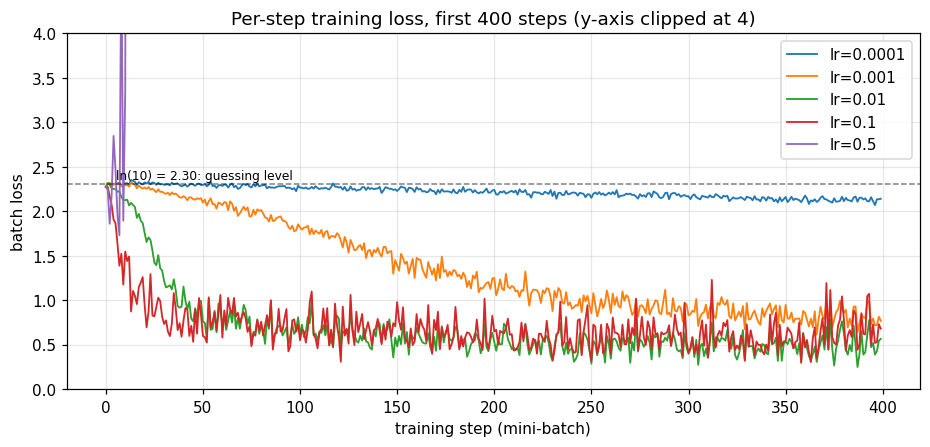

In [6]:
fig, ax = plt.subplots(figsize=(10, 4.2))
for lr, r in results.items():
    ax.plot(r['step_loss'][:400], label=f'lr={lr}', lw=1.2)
ax.axhline(math.log(10), color='k', ls='--', lw=1, alpha=.5)
ax.text(5, math.log(10) + .06, 'ln(10) = 2.30: guessing level', fontsize=8)
ax.set_ylim(0, 4); ax.set_xlabel('training step (mini-batch)'); ax.set_ylabel('batch loss')
ax.set_title('Per-step training loss, first 400 steps (y-axis clipped at 4)'); ax.legend()
plt.show()

### 5b. Epoch-level curves

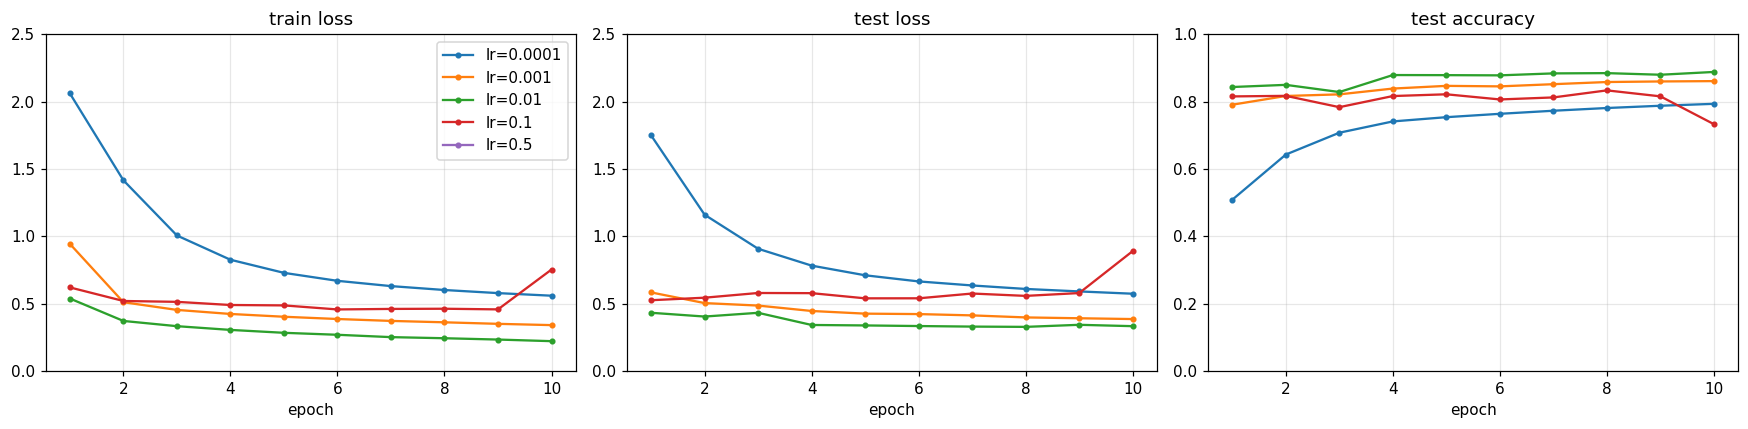

In [7]:
fig, ax = plt.subplots(1, 3, figsize=(16, 4))
for lr, r in results.items():
    e = range(1, len(r['train_loss']) + 1)
    ax[0].plot(e, r['train_loss'], marker='o', ms=3, label=f'lr={lr}')
    ax[1].plot(e, r['test_loss'],  marker='o', ms=3, label=f'lr={lr}')
    ax[2].plot(e, r['test_acc'],   marker='o', ms=3, label=f'lr={lr}')
ax[0].set_title('train loss'); ax[1].set_title('test loss'); ax[2].set_title('test accuracy')
ax[0].set_ylim(0, 2.5); ax[1].set_ylim(0, 2.5); ax[2].set_ylim(0, 1)
for a in ax: a.set_xlabel('epoch')
ax[0].legend(); plt.tight_layout(); plt.show()

### 5c. Summary table

In [8]:
rows = []
for lr, r in results.items():
    if r['diverged']:
        status, tl, ta = 'diverged (NaN)', np.nan, np.nan
    else:
        tl, ta = r['train_loss'][-1], r['test_acc'][-1]
        status = 'not learning' if ta < 0.2 else ('slow' if ta < 0.85 else 'ok')
    rows.append(dict(lr=lr, epochs_completed=len(r['train_loss']), final_train_loss=tl,
                     final_test_acc=ta, verdict=status))
display(pd.DataFrame(rows).set_index('lr').round(4))

,epochs_completed,final_train_loss,final_test_acc,verdict
lr,,,,
0.0001,10,0.5600,0.7933,slow
0.0010,10,0.3418,0.8607,ok
0.0100,10,0.2227,0.8879,ok
0.1000,10,0.7539,0.7329,slow
0.5000,0,NaN,NaN,diverged (NaN)


## 6. What to look for

- **Very small lr (0.0001, 0.001):** the loss falls smoothly but slowly, and after 10 epochs the model is still improving, so it is *undertrained*, not a bad model. Fix: train longer or raise lr.
- **Moderate lr (0.01):** good balance, a steady fall and a high plateau.
- **Large lr (0.1):** the early loss falls fastest, but the per-step curve is jagged and the final accuracy can end up *worse* than with 0.01, because every step overshoots a little.
- **Huge lr (0.5):** the loss blows up and either becomes NaN or sticks near 2.30 (the network is stuck predicting roughly the same output for everything).

A note on momentum: with `momentum=0.9`, the effective step is about 10x the nominal `lr`, which is why 0.1 already behaves like a "big" learning rate here. If you use plain SGD (`momentum=0`), every threshold shifts about 10x higher.

**Rule of thumb:** a good lr is usually just below the largest value that still trains stably.

## 7. Bonus A: find a good lr automatically (LR range test)

Instead of guessing, run **one short pass** where lr grows exponentially every step (1e-5 to 1), and plot loss against lr. A good lr sits on the steep downhill part, *before* the loss turns around and shoots up.

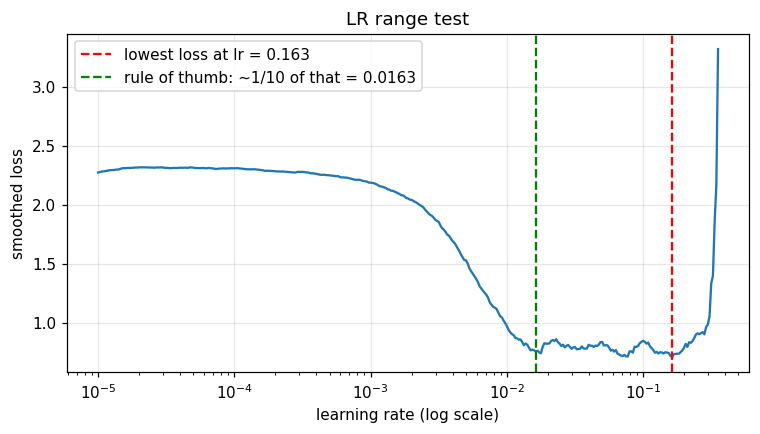

In [9]:
def lr_range_test(lr_min=1e-5, lr_max=1.0, num_steps=400, momentum=0.9, seed=0):
    torch.manual_seed(seed)
    model = MLP().to(device)
    opt = optim.SGD(model.parameters(), lr=lr_min, momentum=momentum)
    gamma = (lr_max / lr_min) ** (1 / num_steps)
    lrs, losses, smooth, best = [], [], None, float('inf')
    it = iter(train_loader)
    lr = lr_min
    for _ in range(num_steps):
        try: x, y = next(it)
        except StopIteration:
            it = iter(train_loader); x, y = next(it)
        for g in opt.param_groups: g['lr'] = lr
        x, y = x.to(device), y.to(device)
        opt.zero_grad()
        loss = criterion(model(x), y)
        loss.backward(); opt.step()
        l = loss.item()
        if not math.isfinite(l): break
        smooth = l if smooth is None else 0.9 * smooth + 0.1 * l      # smooth the noisy loss
        best = min(best, smooth)
        lrs.append(lr); losses.append(smooth)
        if smooth > 4 * best: break                                    # clearly blowing up: stop
        lr *= gamma
    return np.array(lrs), np.array(losses)

lrs_found, losses_found = lr_range_test()
best_lr = lrs_found[losses_found.argmin()]

fig, ax = plt.subplots(figsize=(8, 4))
ax.plot(lrs_found, losses_found)
ax.axvline(best_lr, color='r', ls='--', label=f'lowest loss at lr = {best_lr:.3g}')
ax.axvline(best_lr / 10, color='g', ls='--', label=f'rule of thumb: ~1/10 of that = {best_lr/10:.3g}')
ax.set_xscale('log'); ax.set_xlabel('learning rate (log scale)'); ax.set_ylabel('smoothed loss')
ax.set_title('LR range test'); ax.legend(); plt.show()

Common practice: pick an lr about 10x smaller than where the loss is lowest (or where it starts to shoot up). Compare that with what the sweep in section 5 told you.

## 8. Bonus B: decay the lr during training

Large steps early make fast progress, small steps late allow fine settling. A **scheduler** changes `lr` over time. Call `scheduler.step()` once per epoch. Compare a constant lr of 0.1 with a cosine decay that *starts* at 0.1.

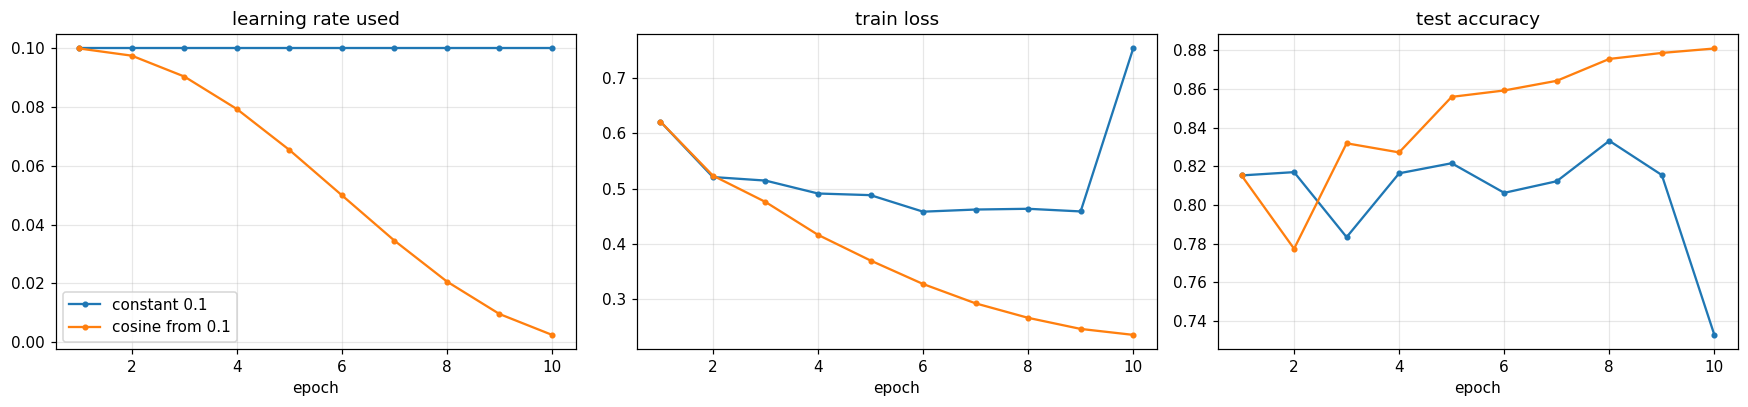

final test acc  constant: 0.7329   cosine: 0.8809


In [10]:
const = run(0.1, epochs=EPOCHS, verbose=False)
cosine = run(0.1, epochs=EPOCHS, verbose=False,
             scheduler_fn=lambda opt: optim.lr_scheduler.CosineAnnealingLR(opt, T_max=EPOCHS))

fig, ax = plt.subplots(1, 3, figsize=(16, 3.8))
for name, r in [('constant 0.1', const), ('cosine from 0.1', cosine)]:
    e = range(1, len(r['train_loss']) + 1)
    ax[0].plot(e, r['lrs'], marker='o', ms=3, label=name)
    ax[1].plot(e, r['train_loss'], marker='o', ms=3, label=name)
    ax[2].plot(e, r['test_acc'], marker='o', ms=3, label=name)
ax[0].set_title('learning rate used'); ax[1].set_title('train loss'); ax[2].set_title('test accuracy')
for a in ax: a.set_xlabel('epoch')
ax[0].legend(); plt.tight_layout(); plt.show()
print('final test acc  constant: %.4f   cosine: %.4f' % (const['test_acc'][-1], cosine['test_acc'][-1]))

## Takeaways

1. `lr` controls the size of each update: `w <- w - lr * grad`.
2. **Too small:** smooth but slow, so the model is undertrained. **Too large:** jagged, worse final accuracy, or divergence (NaN, or stuck at loss 2.30).
3. The best `lr` is usually the largest one that still trains stably, and it depends on the optimizer, momentum, and batch size.
4. Watch the training loss curve first. It tells you right away whether `lr` is the problem.
5. Tools: the LR range test finds a good starting value, and schedulers let you start high and finish low.

## Exercises
1. Set `momentum=0` in `run()` and repeat the sweep. Which lr values now look "good"? (Hint: shift everything about 10x.)
2. Repeat the sweep with `optim.Adam`. Which range of lr works? How does it compare with SGD?
3. Run lr=0.1 with 3 different seeds. Are the curves reliably jagged, or does it depend on the seed?
4. Change the batch size to 512. Does the best lr go up or down?
5. Try `StepLR(opt, step_size=3, gamma=0.5)` instead of cosine.